In [1]:
import glob

import numpy as np
import pandas as pd
from skimage import io
import matplotlib.pyplot as plt

from corebreakout import defaults
from corebreakout import CoreSegmenter
from corebreakout.datasets import PolygonDataset

Using TensorFlow backend.


In [2]:
model_dir = defaults.TRAIN_DIR / 'cb_default20190930T1556'

weights_path = model_dir / 'mask_rcnn_cb_default_0100.h5'

In [3]:
segmenter = CoreSegmenter(model_dir, weights_path)

W0930 14:47:53.247637 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:517: The name tf.placeholder is deprecated. Please use tf.compat.v1.placeholder instead.

W0930 14:47:53.261007 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:74: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.

W0930 14:47:53.263579 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:4138: The name tf.random_uniform is deprecated. Please use tf.random.uniform instead.

W0930 14:47:53.278720 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:1919: The name tf.nn.fused_batch_norm is d

Building MRCNN model from directory: /home/ross/Dropbox/models/corebreakout/pretrain/cb_default20190930T1243


W0930 14:47:55.026629 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:2018: The name tf.image.resize_nearest_neighbor is deprecated. Please use tf.compat.v1.image.resize_nearest_neighbor instead.

W0930 14:47:55.303639 139927075710784 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/mask_rcnn-2.1-py3.7.egg/mrcnn/model.py:341: The name tf.log is deprecated. Please use tf.math.log instead.

W0930 14:47:55.310107 139927075710784 deprecation.py:323] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/mask_rcnn-2.1-py3.7.egg/mrcnn/model.py:399: add_dispatch_support.<locals>.wrapper (from tensorflow.python.ops.array_ops) is deprecated and will be removed in a future version.
Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where
W0930 14:47:55.314598 139927075710784 deprecation.py:506] From /h

Loading model weights from file: /home/ross/Dropbox/models/corebreakout/pretrain/cb_default20190930T1243/mask_rcnn_cb_default_0100.h5
Re-starting from epoch 100


In [4]:
test_dataset = PolygonDataset()
test_dataset.collect_annotated_images(defaults.DATASET_DIR, 'test')
test_dataset.prepare()

print(test_dataset)


 PolygonDataset
Image count : 5
Class count : 3
  0. BG                                                
  1. col                                               
  2. tray                                              


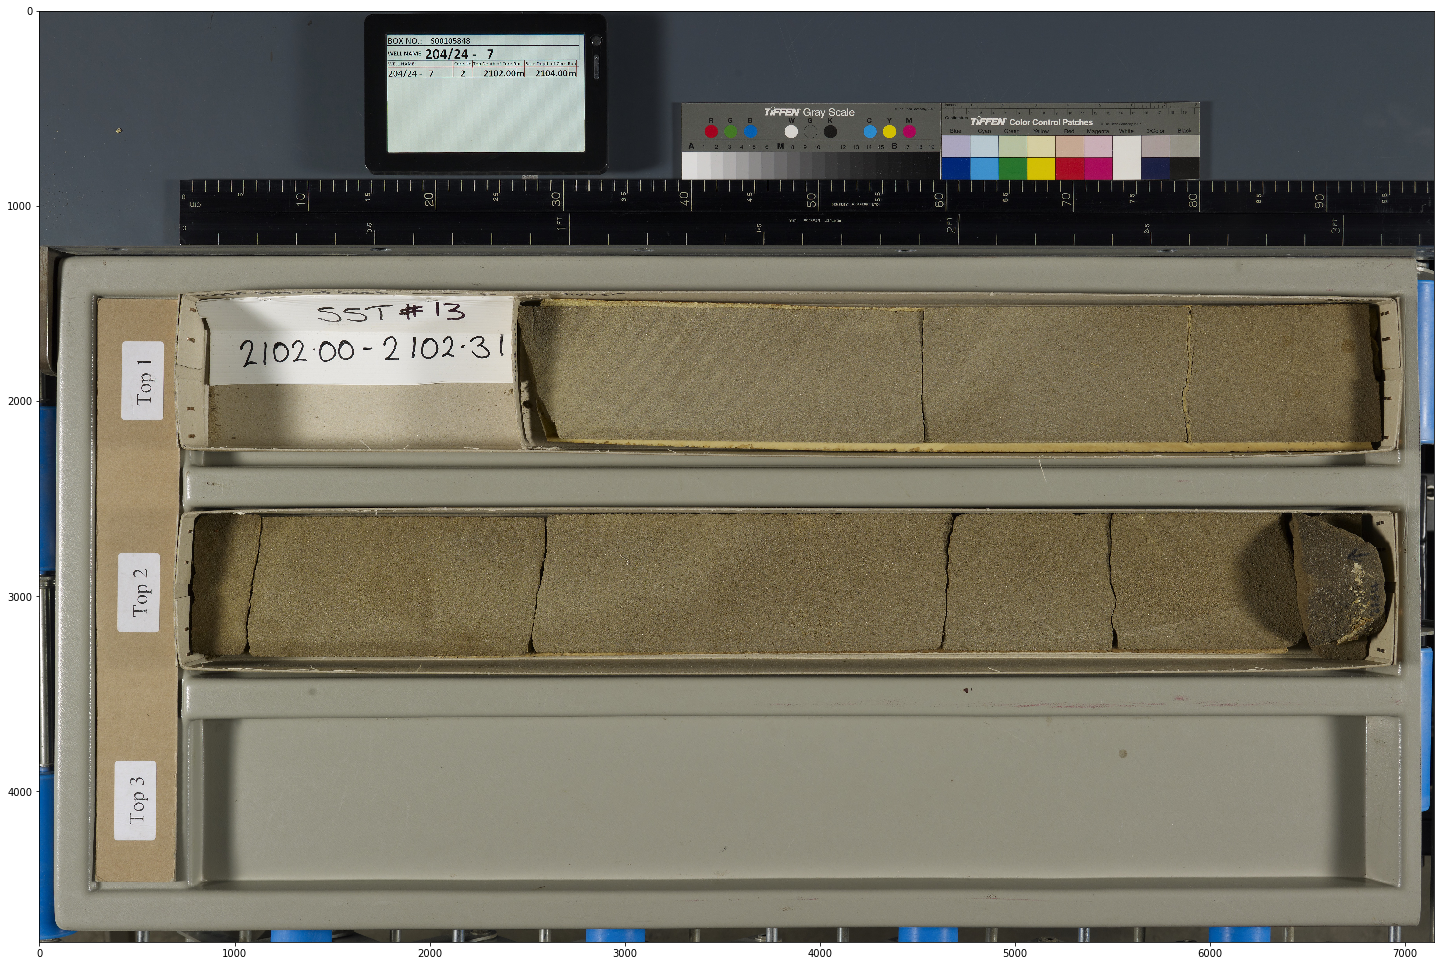

In [5]:
test_img = test_dataset.load_image(2)

fig, ax = plt.subplots(figsize=(25,25))
ax.imshow(test_img)

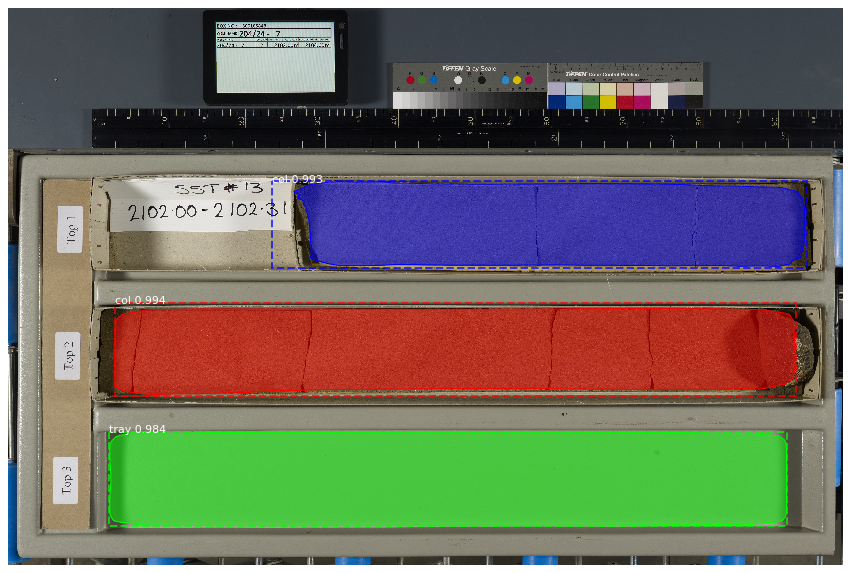

(2102.0, 2103.0) (2103.0, 2104.0) 0.0


In [6]:
column = segmenter.segment(test_img, [2102.,2104.], show=True)

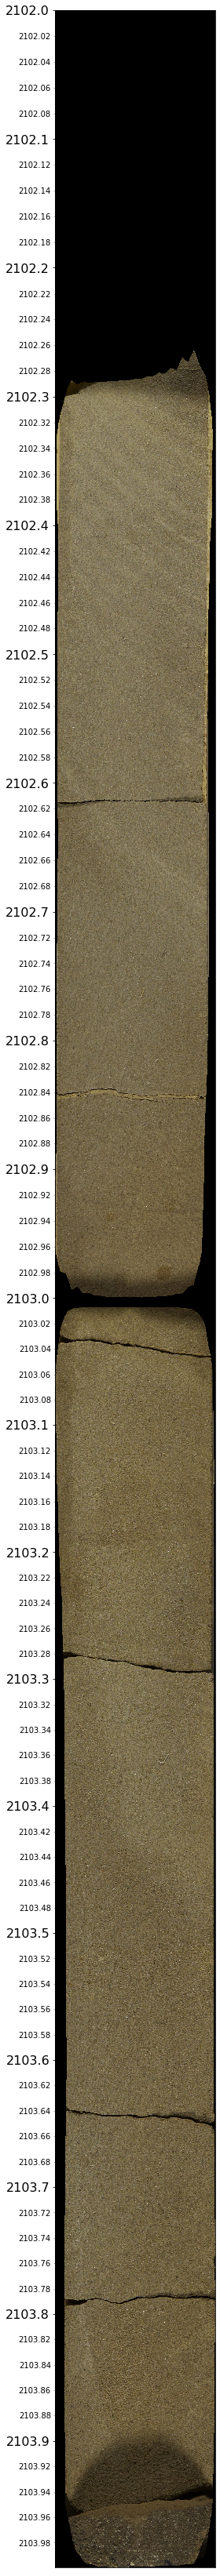

In [9]:
fig, ax = column.plot(figsize=(15, 60), minor_precision=0.02, minor_tick_size=10)

In [12]:
fig.savefig('/home/ross/Pictures/stacked_column.png')